In [1]:
'''
rate limit calculation (first step: cnn efficiency)
'''

'\nrate limit calculation (first step: cnn efficiency)\n'

In [2]:
import os
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import scipy.ndimage as snm


import precision_recall as pr
import importlib

# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os
# import implantation_functions as imp
# from tensorflow import keras
# import get_postage_stamps as gpsf
# from scipy.ndimage import sobel

In [3]:
def fake_heatmap(save_name, folds=False, color1='thistle', color2='grey',tlight='white', tdark='black'):
    # Define your two endpoint colors
    # color_low  = color2   # for negative values
    # color_high = color1   #paleturquoise    # for positive values
    
    # Create the colormap dictionary
    # colors = [color_low , color_high]
    # my_cmap = LinearSegmentedColormap.from_list('my_diverging', colors)

    our_feat_te = np.load("/lustre/lrspec/ZTF_data/saved_loss/our_feat_te_"+save_name+".npy")
    our_bness_te = np.load("/lustre/lrspec/ZTF_data/saved_loss/our_bness_te_"+save_name+".npy")
    our_lens_te = np.load("/lustre/lrspec/ZTF_data/saved_loss/our_lens_te_"+save_name+".npy")

    our_targ_te = np.load("/lustre/lrspec/ZTF_data/saved_loss/our_targ_te_"+save_name+".npy") 
    targ_te = np.load("/lustre/lrspec/ZTF_data/saved_loss/targ_te_"+save_name+".npy") 
    if folds==False:
        our_pred_te_max = np.load("/lustre/lrspec/ZTF_data/saved_loss/our_pred_te_max_"+save_name+".npy")
    else:
        #can't determine the max until i average predictions
        foldses = ["0","1","2","3","4"]
        label_pred_tes = []
        for fold in foldses:
            label_pred_tes.append(np.load("/lustre/lrspec/ZTF_data/saved_loss/label_pred_te_"+save_name+"_fold_"+str(fold)+".npy"))
        label_pred_te = np.average(np.array(label_pred_tes),axis=0)
        # print(label_pred_te.shape)
        targ_te = np.load('/lustre/lrspec/ZTF_data/saved_loss/targ_te_'+save_name+'.npy')
        mask = np.sum(([targ_te==2],[targ_te==1]), axis=0)[0]
        # print(mask)
        
        # return label_pred_te, mask
        our_pred_te_max = np.argmax(label_pred_te[mask.astype(bool)], axis=1)
        # print("mask above")
        # print(label_pred_te[mask])
        # print("above should be fine")
        # print(our_pred_te_max)
                    
                    
    
    length_values = np.unique(our_lens_te)
    trues = []
    fails = []
    for i in range(len(our_targ_te)):
        if our_targ_te[i] == our_pred_te_max[i]:
            trues.append([our_bness_te[i], our_lens_te[i]])
        else:
            fails.append([our_bness_te[i], our_lens_te[i]])
    fails = np.array(fails)
    trues = np.array(trues)

    # Given nonlinear brightness values
    brightness_values = np.unique(our_bness_te)
    length_values = np.unique(our_lens_te)

    # # Given nonlinear brightness and length values
    # brightness_values = np.array([0.8, 0.9, 0.99, 1.01, 1.1, 2, 5, 10])
    # length_values = np.array([1, 2, 3, 4, 5, 6, 7, 8])  # Example length values

    # Create bins for brightness and length
    brightness_bins = np.concatenate(
        [
            [brightness_values[0] - 0.1],
            (brightness_values[:-1] + brightness_values[1:]) / 2,
            [brightness_values[-1] + 0.1],
        ]
    )

    # length_bins = np.concatenate(
    #     [
    #         [length_values[0] - 0.5],
    #         (length_values[:-1] + length_values[1:]) / 2,
    #         [length_values[-1] + 0.5],
    #     ]
    # )

    # Example data: Replace these with your actual data
    correct_detections = trues  # Array of correctly detected (brightness, length)
    incorrect_detections = fails  # Array of incorrectly detected (brightness, length)

    # Create 2D histogram for correct and total detections
    correct_hist, xedges = np.histogram(
        correct_detections[:, 0],
        bins=brightness_bins,
    )

    total_hist, _ = np.histogram(
        np.vstack((correct_detections, incorrect_detections))[:, 0],
        bins=brightness_bins,
    )

    # Calculate efficiency
    efficiency = correct_hist / total_hist
    

    # Calculate error (using Poisson approximation)
    error = np.sqrt(efficiency * (1 - efficiency) / total_hist)
    return efficiency, error, brightness_values

    

In [4]:
save_name='offset_sat_newhparam_b50_allstamps_satdumbsplit_folds'

In [5]:
eff, err, brightness_values = fake_heatmap(save_name, folds=True, color1='#BCE3DD', color2='#164E5C',tlight='#FFFFFF', tdark='#61430B')

In [6]:
%matplotlib inline

In [23]:
plt.errorbar?

Signature:
plt.errorbar(
    x,
    y,
    yerr=None,
    xerr=None,
    fmt='',
    ecolor=None,
    elinewidth=None,
    capsize=None,
    barsabove=False,
    lolims=False,
    uplims=False,
    xlolims=False,
    xuplims=False,
    errorevery=1,
    capthick=None,
    *,
    data=None,
    **kwargs,
)
Docstring:
Plot y versus x as lines and/or markers with attached errorbars.

*x*, *y* define the data locations, *xerr*, *yerr* define the errorbar
sizes. By default, this draws the data markers/lines as well the
errorbars. Use fmt='none' to draw errorbars without any data markers.

.. versionadded:: 3.7
   Caps and error lines are drawn in polar coordinates on polar plots.


Parameters
----------
x, y : float or array-like
    The data positions.

xerr, yerr : float or array-like, shape(N,) or shape(2, N), optional
    The errorbar sizes:

    - scalar: Symmetric +/- values for all data points.
    - shape(N,): Symmetric +/-values for each data point.
    - shape(2, N): Separate - an

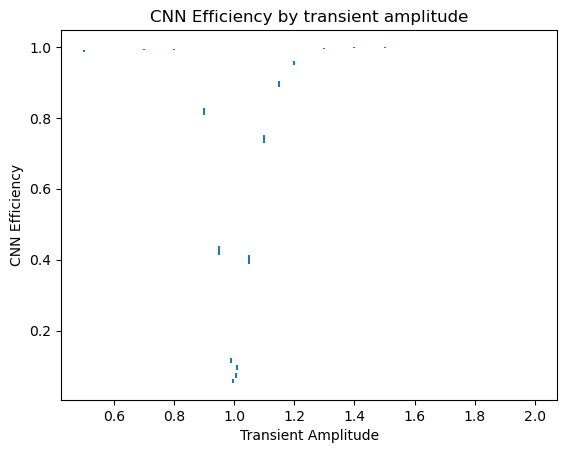

In [32]:
plt.title('CNN Efficiency by transient amplitude')
plt.errorbar(brightness_values, eff, yerr=err, linestyle='', ms=20)
plt.xlabel('Transient Amplitude')
plt.ylabel('CNN Efficiency')
plt.show()


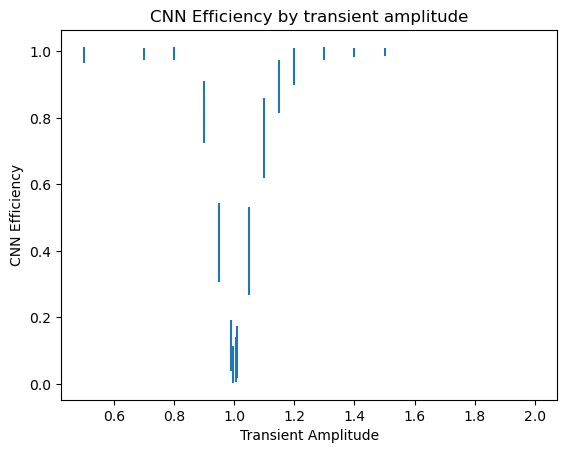

In [51]:
plt.title('CNN Efficiency by transient amplitude')
plt.errorbar(brightness_values, eff, yerr=10*err, linestyle='', ms=20)
plt.xlabel('Transient Amplitude')
plt.ylabel('CNN Efficiency')
plt.show()


In [49]:
(.024+.033*(1-.024))

0.056208

In [38]:
(1-.024)*(1-.033)

0.943792

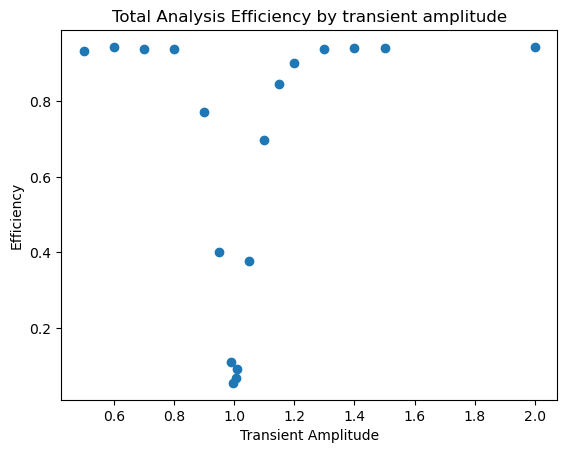

In [53]:
plt.title('Total Analysis Efficiency by transient amplitude')
plt.xlabel('Transient Amplitude')
plt.ylabel('Efficiency')
plt.plot(brightness_values, eff*.943792, 'o')
plt.show()

In [ ]:
2.996/(eff*star_hours)

In [7]:
star_hours = 1128

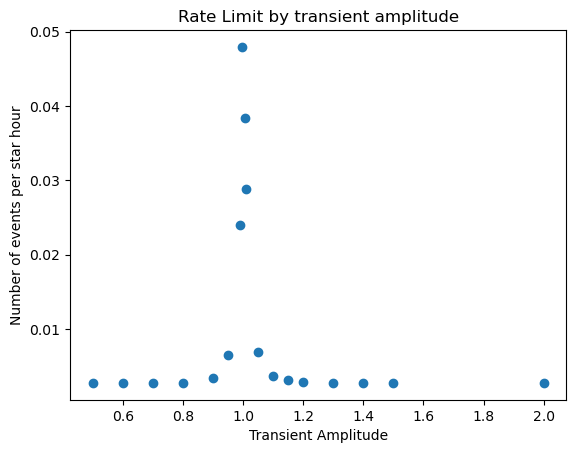

In [56]:
plt.title('Rate Limit by transient amplitude')
plt.xlabel('Transient Amplitude')
plt.ylabel('Number of events per star hour')
plt.plot(brightness_values, 2.996/(eff*.943792*star_hours), 'o')
plt.show()

In [ ]:
brightness_values[:8]

In [8]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [40]:
np.min(2.996/(eff*.943792*star_hours))

0.0028142094537719395

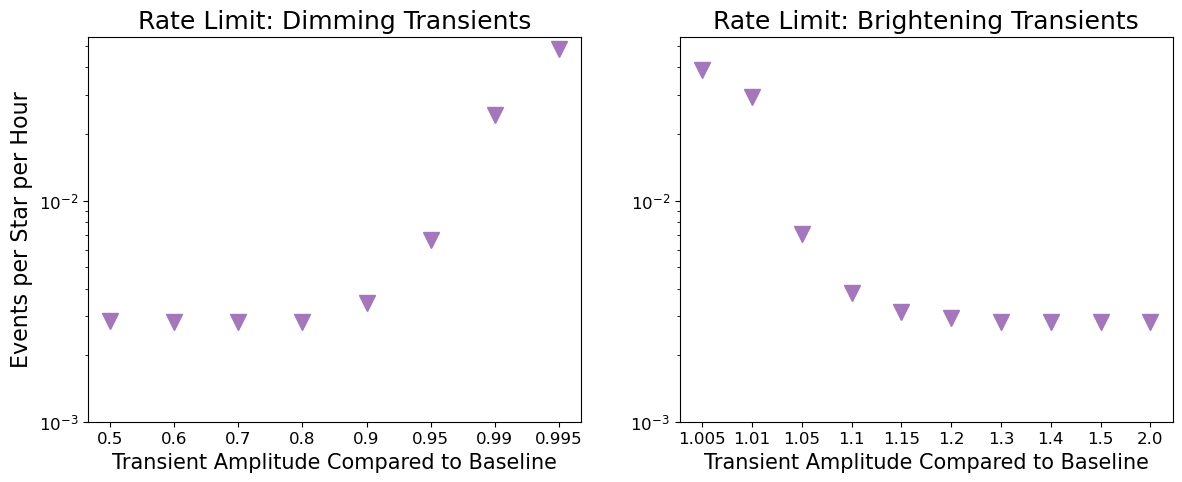

In [9]:
plt.rcParams.update({'font.size': 12})
fig, ax = plt.subplots(1,2, figsize=(14,5))
# fig.set_title('Rate Limit by transient amplitude')
ax[0].set_title('Rate Limit: Dimming Transients', size=18)
ax[1].set_title('Rate Limit: Brightening Transients', size=18)
ax[0].set_xlabel('Transient Amplitude Compared to Baseline', size=15)
ax[1].set_xlabel('Transient Amplitude Compared to Baseline', size=15)
# ax[1].set_ylabel('Number of events per star hour')
ax[0].set_ylabel('Events per Star per Hour', size=16)
ax[0].plot(brightness_values[:8].astype('str'), 2.996/(eff*.943792*star_hours)[:8], 'v', c='#A477BD', ms=12)
ax[1].plot(brightness_values[8:].astype('str'), 2.996/(eff*.943792*star_hours)[8:], 'v', c='#A477BD', ms=12)
ax[0].set_ylim(0.001,.055)
ax[1].set_ylim(0.001,.055)
# for axis in ax:
#     ax.set_textsize('10')
ax[0].set_yscale('log')
ax[1].set_yscale('log')
plt.show()

In [ ]:
plt.rcParams.update({'font.size': 12})
fig, ax = plt.subplots(1,2, figsize=(14,5))
# fig.set_title('Rate Limit by transient amplitude')
ax[0].set_title('Rate Limit: Dimming Transients', size=18)
ax[1].set_title('Rate Limit: Brightening Transients', size=18)
ax[0].set_xlabel('Transient Amplitude Compared to Baseline', size=15)
ax[1].set_xlabel('Transient Amplitude Compared to Baseline', size=15)
# ax[1].set_ylabel('Number of events per star hour')
ax[0].set_ylabel('Events per Star per Hour', size=16)
ax[0].plot(brightness_values[:8].astype('str'), 2.996/(eff*.943792*star_hours)[:8], 'v', c='#A477BD', ms=12)
ax[1].plot(brightness_values[8:].astype('str'), 2.996/(eff*.943792*star_hours)[8:], 'v', c='#A477BD', ms=12)
ax[0].set_ylim(0.001,.055)
ax[1].set_ylim(0.001,.055)
# for axis in ax:
#     ax.set_textsize('10')
ax[0].set_yscale('log')
ax[1].set_yscale('log')
plt.show()

In [75]:
brightness_values[8:]-1

array([0.005, 0.01 , 0.05 , 0.1  , 0.15 , 0.2  , 0.3  , 0.4  , 0.5  ,
       1.   ])

In [76]:
1-brightness_values[:8]

array([0.5  , 0.4  , 0.3  , 0.2  , 0.1  , 0.05 , 0.01 , 0.005])

In [39]:
total_from_partial = 19 + 28518 +   412
from_partial_wd = 412
from_partial_quasar = 19
quasar_ratio = from_partial_quasar/total_from_partial
wd_ratio = from_partial_wd/total_from_partial



In [76]:
quasar_ratio*star_hours

0.7403364537635152

In [77]:
wd_ratio*star_hours

16.053611523714117

In [81]:
star_total = 15256

In [82]:
wd_ratio*star_total

217.1222494732115

In [83]:
quasar_ratio*star_total

10.012919271822861

In [78]:
star_hours

1128

In [44]:
def get_event_rate(eff, star_hours_input):
    #do partial eff to match brightness values
    return 2.996/(eff*.943792*star_hours_input)

In [84]:
brightness_values[8:]-1, get_event_rate(eff[8:],star_hours)

(array([0.005, 0.01 , 0.05 , 0.1  , 0.15 , 0.2  , 0.3  , 0.4  , 0.5  ,
        1.   ]),
 array([0.03892551, 0.02924768, 0.00703552, 0.00380376, 0.00314431,
        0.00294609, 0.00282935, 0.0028221 , 0.00281996, 0.00281421]))

In [85]:
1-brightness_values[:8], get_event_rate(eff[:8],star_hours)

(array([0.5  , 0.4  , 0.3  , 0.2  , 0.1  , 0.05 , 0.01 , 0.005]),
 array([0.00284449, 0.00281421, 0.0028344 , 0.00283412, 0.00343914,
        0.0066103 , 0.02429181, 0.04857217]))

In [86]:
brightness_values[8:]-1, get_event_rate(eff[8:],quasar_ratio*star_hours)

(array([0.005, 0.01 , 0.05 , 0.1  , 0.15 , 0.2  , 0.3  , 0.4  , 0.5  ,
        1.   ]),
 array([59.30814227, 44.56268402, 10.71954598,  5.79552689,  4.79076962,
         4.48875924,  4.31088668,  4.29984593,  4.29658694,  4.28781839]))

In [87]:
1-brightness_values[:8], get_event_rate(eff[:8],quasar_ratio*star_hours)

(array([0.5  , 0.4  , 0.3  , 0.2  , 0.1  , 0.05 , 0.01 , 0.005]),
 array([ 4.33395008,  4.28781839,  4.31858695,  4.31816224,  5.23997994,
        10.07166134, 37.01176574, 74.00609631]))

In [88]:
brightness_values[8:]-1, get_event_rate(eff[8:],wd_ratio*star_hours)

(array([0.005, 0.01 , 0.05 , 0.1  , 0.15 , 0.2  , 0.3  , 0.4  , 0.5  ,
        1.   ]),
 array([2.73508423, 2.05507523, 0.49434799, 0.26726944, 0.22093355,
        0.20700589, 0.19880303, 0.19829387, 0.19814357, 0.1977392 ]))

In [89]:
1-brightness_values[:8], get_event_rate(eff[:8],wd_ratio*star_hours)

(array([0.5  , 0.4  , 0.3  , 0.2  , 0.1  , 0.05 , 0.01 , 0.005]),
 array([0.19986663, 0.1977392 , 0.19915814, 0.19913855, 0.24164956,
        0.46446982, 1.70685327, 3.4129025 ]))

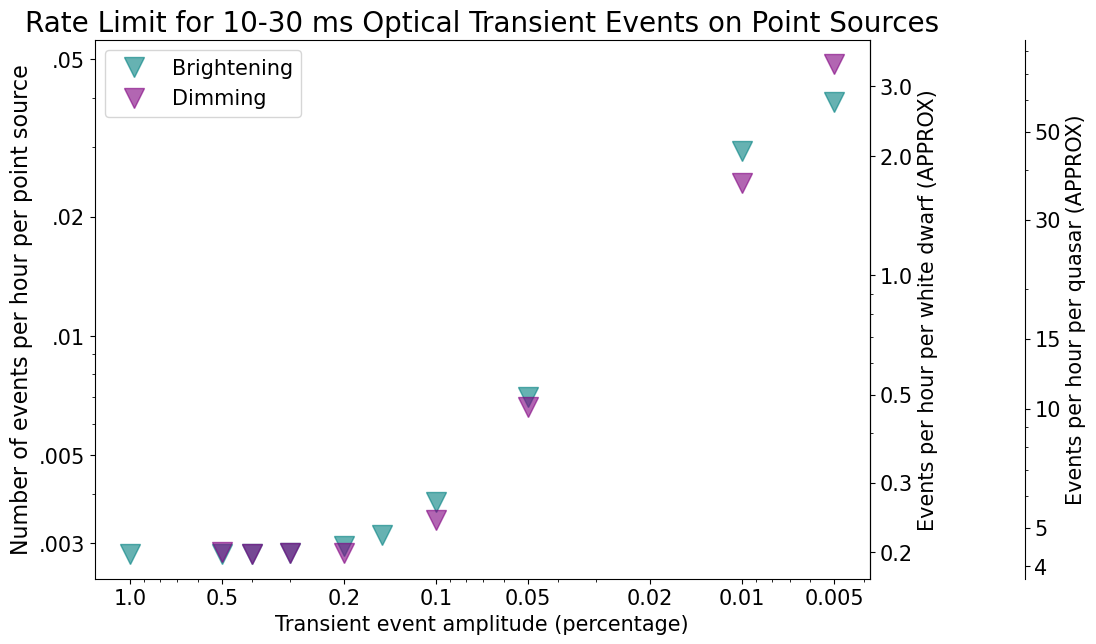

In [74]:
fig, ax = plt.subplots(1,1)
ax.set_title('Rate Limit for 10-30 ms Optical Transient Events on Point Sources', size=20)
ax.set_xlabel('Transient event amplitude (percentage)', size=15)
ax.set_ylabel('Number of events per hour per point source', size=16)
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_yticks([.003,.005,.01,.02,.05], ['.003','.005','.01','.02','.05'], size=15)
ax.set_xticks([1,.5,.2,.1,.05,.02,.01,.005], np.array([1,.5,.2,.1,.05,.02,.01,.005],).astype(str), size=15)
ax.plot(brightness_values[8:]-1, get_event_rate(eff[8:],star_hours), 'v', c='teal', ms=15,label='Brightening', alpha=.6)
ax.plot(1-brightness_values[:8], get_event_rate(eff[:8],star_hours), 'v', c='purple', ms=15,label='Dimming', alpha=.6)
ax.legend(fontsize=15)
plt.gca().invert_xaxis()

def source_hour_to_quasar_hour(y):
    return y/quasar_ratio

def qhtsh(y):
    return y*quasar_ratio

def source_hour_to_wd_hour(y):
    return y/wd_ratio

def wdhtsh(y):
    return y*wd_ratio

# def source_hour_to_wd_hour(y):
#     return y*4



secax_y = ax.secondary_yaxis(
     1.2,functions=(source_hour_to_quasar_hour, qhtsh))
secax_y.set_ylabel('Events per hour per quasar (APPROX)', size=15)
quasar_ticks = [4, 5,10,15, 30, 50]
secax_y.set_yticks(quasar_ticks, np.array(quasar_ticks).astype(str), size=15)


# use of a float for the position:
secax_y2 = ax.secondary_yaxis('right',
     functions=(source_hour_to_wd_hour, wdhtsh))
secax_y2.set_ylabel('Events per hour per white dwarf (APPROX)', size=15)
wd_ticks = [.2,.3,.5,1,2,3]
secax_y2.set_yticks(wd_ticks, np.array(wd_ticks).astype(str), size=15)



plt.show()